# Sea surface height in ACCESS-OM3 and observations

## Setting up

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/5

https://access-nri.zulipchat.com/#narrow/channel/470332-ocean-seaice/topic/Evaluation/near/512462625

 - SSH - SEALEVEL_GLO_PHY_L4_MY_008_047 is in kj13 /g/data/kj13/datasets/cosima/CMEMS and have started a CMORiser in ESMValTool working for monthly
 - AVISO Altimetry Antarctic -kj13 : /g/data/kj13/datasets/cosima/AVISO-Altimetry

Both the above are also in:
 - /g/data/av17/access-nri-temporary/OM3/CMEMS
 - /g/data/av17/access-nri-temporary/OM3/AVISO-Altimetry

Hacked from:
 - https://cosima-recipes.readthedocs.io/en/latest/02-Appetisers/Compare_SSH_model_obs.html (nb: `ua8` is no longer accepting new members)
 - https://github.com/ACCESS-Community-Hub/access-om3-paper-1/blob/main/notebooks/SST.ipynb

Related chat:
 - https://access-nri.zulipchat.com/#narrow/channel/470332-ocean-seaice/topic/Evaluation/near/544659613
 - https://github.com/COSIMA/cosima-recipes/issues/549

NB: with 25km monthly output runs okay on an ARE "large" job.

**If using the daily sattelite obs one needs to use `normalsr` queue with 104 cores/496 Gb**

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/"
nbname = "SSH.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from model_agnostic import patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs

In [4]:
import xarray as xr
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client
import cftime
import os
import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft
from textwrap import wrap
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default
import glob

In [5]:
client = Client(threads_per_worker=1)
from model_agnostic import patch_dask_workers
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:40771,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:37305,Total threads: 1
Dashboard: http://127.0.0.1:44037/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:45853,


In [6]:
#here we set the years that we are interested in

start_time = '1993-01-01'
end_time = '2023-12-31'

start_year=int(start_time.split('-')[0])
end_year=int(end_time.split('-')[0])


## SSH from 0.25$^{\circ}$ ACCESS-OM3 model output

In [7]:
from exptdata_access import get_exptname_from_path
exptname = get_exptname_from_path(esm_file)

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

In [8]:
exptname

'MC_8km_jra_ryf-test2-expt-c349f800'

In [9]:
from model_agnostic import get_lon_lat_from_catalog
geolon, geolat = get_lon_lat_from_catalog(datastore)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e53c9917f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e53c9f00e0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e53c515370>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e53c9eede0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e53c9ee0f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e53c516180>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e53781b680>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [10]:
variable = "zos"
model_all = datastore.search(variable=variable).to_dask(
    xarray_open_kwargs = dict(
        chunks={"time": -1},
        decode_timedelta=True
    ),
    xarray_combine_by_coords_kwargs=dict(
        compat="override",
        data_vars="minimal",
        coords="minimal"
    )
)[variable].cf.assign_coords({ "longitude": geolon, "latitude": geolat })

In [11]:
#model_all

In [12]:
# omit latitudes with grid bug https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
# -- only affects the 25km-iaf-test-for-AK-expt-7df5ef4c experiment specifically
if exptname == "25km-iaf-test-for-AK-expt-7df5ef4c":
    model_all = model_all.isel(yh=slice(10, None))
    geolon = geolon.isel(yh=slice(10, None))
    geolat = geolat.isel(yh=slice(10, None))

In [13]:
# for IAF
model_all = model_all.convert_calendar("proleptic_gregorian", use_cftime=True)

In [14]:
model_all.time.values[0] # initial date in data

cftime.DatetimeProlepticGregorian(1900, 1, 16, 12, 0, 0, 0, has_year_zero=True)

In [15]:
model_all.time.values[-1] # final date in data

cftime.DatetimeProlepticGregorian(1909, 12, 16, 12, 0, 0, 0, has_year_zero=True)

In [16]:
# set time range

# timerange = slice(cftime.DatetimeNoLeap(1942, 1, 1, 0, 0, 0, 0),
#                   cftime.DatetimeNoLeap(1952, 1, 1, 0, 0, 0, 0))
# timerange = slice(None, None)
# datestop = model_all.time.values[-1] # final date in data

datestart= cftime.DatetimeProlepticGregorian(start_year, 1,  16, 12, 0, 0, 0, has_year_zero=True)  # to match OM2 IAF run
datestop = cftime.DatetimeProlepticGregorian(end_year, 12, 16, 12, 0, 0, 0, has_year_zero=True)  # to match OM2 IAF run
timerange = slice(datestart, datestop)

In [17]:
datestart

cftime.DatetimeProlepticGregorian(1993, 1, 16, 12, 0, 0, 0, has_year_zero=True)

In [18]:
datestop

cftime.DatetimeProlepticGregorian(2023, 12, 16, 12, 0, 0, 0, has_year_zero=True)

In [19]:
model_all = model_all.sel(time=timerange)

In [20]:
%%time
model_mean = model_all.mean('time').load()

CPU times: user 1.6 s, sys: 653 ms, total: 2.25 s
Wall time: 2 s


In [21]:
%%time
# this should really use the square field (although it makes the om2 comparison apples-to-oranges)
model_std = model_all.std('time').load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/g/data/xp65/pu

CPU times: user 508 ms, sys: 344 ms, total: 853 ms
Wall time: 867 ms


## SSH from 0.25$^{\circ}$ ACCESS-OM2 model output

In [22]:
# SSH variable in ACCESS-OM2 models
variable = 'sea_level'

catalog = intake.cat.access_nri
var_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable=variable, frequency='1mon')
ds = var_search.to_dask()
ssh025 = ds[variable].sel(time=slice(start_time, end_time))

You can see we have a very large number of chunks, so lets rechunk.

In [23]:
ssh025 = ssh025.chunk({'time': 'auto'})

In [24]:
%%time
#this cell will take a bit (few minutes)
# 0.25 deg:
ssh025_mean = ssh025.mean(dim='time').load()
ssh025_std  = ssh025.std(dim='time', skipna=False).load()

CPU times: user 2.79 s, sys: 2.01 s, total: 4.8 s
Wall time: 9.5 s


In [25]:
var_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable="area_t")
ds = var_search.search(path=var_search.df["path"][0]).to_dask()
geolon_t_025 = ds.geolon_t
geolat_t_025 = ds.geolat_t

ssh025_mean = ssh025_mean.assign_coords({"geolon_t": geolon_t_025, "geolat_t": geolat_t_025})
ssh025_std = ssh025_std.assign_coords({"geolon_t": geolon_t_025, "geolat_t": geolat_t_025})

## Read in observations

In [26]:
import numpy as np
filenames=[]

#for debugging if you want a tiny dataset
# for year in np.arange(start_year,1994+1):
#     filenames.append(sorted(glob.glob("/g/data/av17/access-nri-temporary/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_202411/"+str(year)+"/11/*1101_*15*.nc")))

#for daily data
for year in np.arange(start_year,end_year+1):
    #print(year)
    filenames.append(sorted(glob.glob("/g/data/av17/access-nri/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_202411/"+str(year)+"/*/*.nc")))

#for monthly data
# for year in np.arange(start_year,end_year+1):
#     #print(year)
#     filenames.append(sorted(glob.glob("/g/data/av17/access-nri-temporary/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1M-m_202411/"+str(year)+"/*.nc")))

#make list of lists into just a list
filenames = [item for sublist in filenames for item in sublist]

In [27]:
%%time
#this was taking ages on daily data, so Dougie suggested adding: data_vars='minimal', coords='minimal', compat='override' -- should avoid any issues with messy metadata -- see docs: https://docs.xarray.dev/en/stable/generated/xarray.open_mfdataset.html
cmems = xr.open_mfdataset(filenames, parallel=True,concat_dim="time", combine="nested", data_vars='minimal', coords='minimal', compat='override',chunks="auto")

#even betterer (I think these extra ones actually slowed it down a bit?)
#concat_dim="time", combine="nested", data_vars='minimal', coords='minimal', compat='override'

#faster with 28 cores compared to 14 (~1.5 minutes)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14c307423d10>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x153ffb78f590>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x153f86ac6fc0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14c5e72849e0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14c5e765aae0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1526191330b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151f2abbd9d0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1491a60761e0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1491a41a1070>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


CPU times: user 6min 57s, sys: 4min 1s, total: 10min 59s
Wall time: 12min 23s


In [28]:
#filenames

In [29]:
# for daily files
# The absolute dynamic topography is the sea surface height above geoid; the adt is obtained as follows: adt=sla+mdt where mdt is the mean dynamic topography; see the product user manual for details
obs_ssh = cmems.adt 
obs_ssh = obs_ssh.rename('adt_cmems')

# for daily files
# obs_ssh = cmems.sla 
# obs_ssh = obs_ssh.rename('adt_cmems')


In [30]:
%%time
#on daily data this cell didn't run properly with 28 cores/252 gb. Needed `normalsr` queue with 104 cores/496 Gb
obs_ssh_mean = obs_ssh.mean(dim='time').load()
obs_ssh_std  = obs_ssh.std(dim='time', skipna=False).load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 21.50 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 21.50 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


CPU times: user 5min 39s, sys: 4min 25s, total: 10min 4s
Wall time: 19min 28s


In [31]:
#from Anton -- could use this kind of command to reduce the obs down to the model frequency but I think it makes more sense to use ssh^2 fields from model.
#obs_ssh_mean= obs_ssh.groupbyt('time.month').mean('time').std(dim='time', skipna=False)
#obs_ssh_std = obs_ssh.groupbyt('time.month').mean('time').std(dim='time', skipna=False)

#AS: sorry - this should be a resample not a groupby !
#AS: groupby would give a climatology (a monthly mean of all years). resample would give a mean for every month (e.g like change from daily to monthly data)

## Plot ACCESS-OM2, ACCESS-OM3 and obs


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SSH_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SSH.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SSH.md successfully.
CPU times: user 1min 17s, sys: 19.1 s, total: 1min 36s
Wall time: 1min 17s


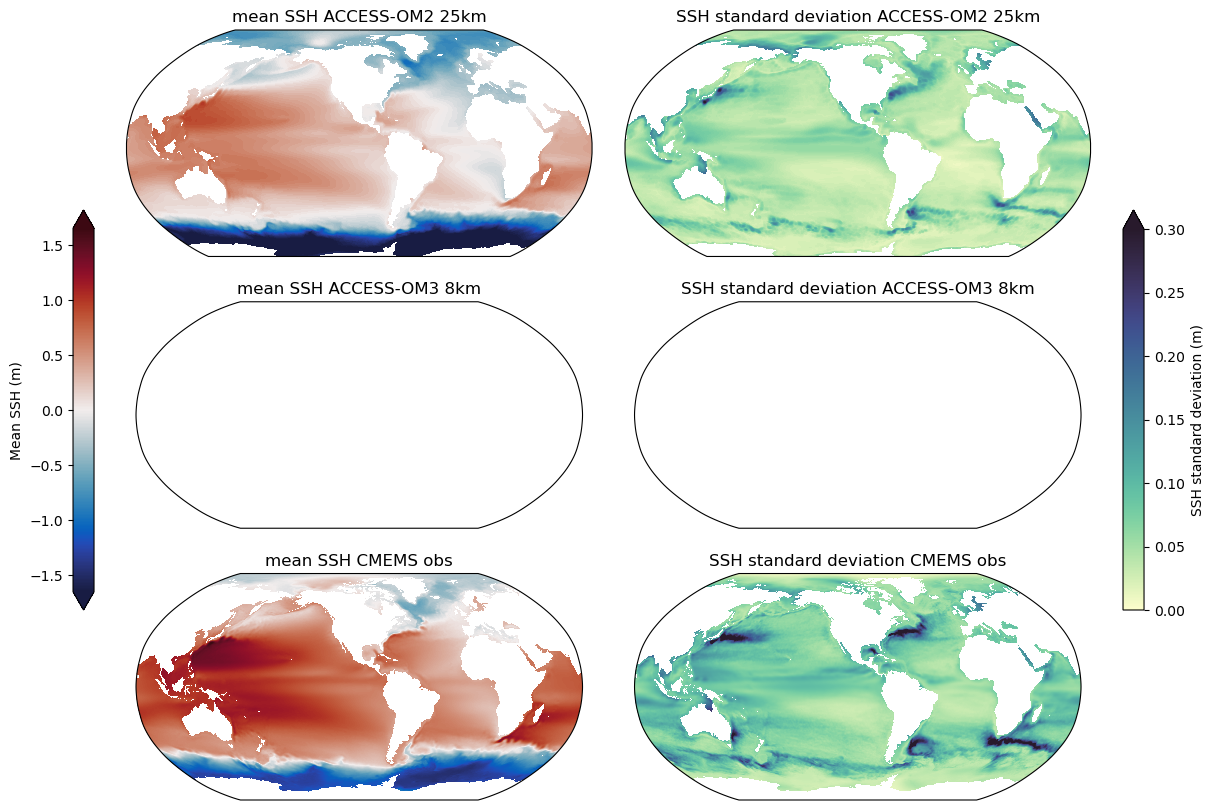

In [32]:
%%time

# nominal resolution from the model grid, so titles are right for any OM3 resolution
nx = model_mean.sizes["xh"]
om3_res = {360: "100km", 1440: "25km", 4320: "8km"}.get(nx)

projection = ccrs.Robinson(central_longitude=-100)

fig, axes = plt.subplots(nrows = 3, ncols = 2, figsize = (14, 10),
                         subplot_kw={'projection': projection})
plt.subplots_adjust(wspace=-0.15)

max_std = 0.3
max_mean = 1.65

# mean SSH plots
ax = axes[0, 0]
p1 = ssh025_mean.plot.contourf(
    ax = ax,
    x = "geolon_t",
    y = "geolat_t",
    levels = 100,
    vmin = -max_mean,
    vmax = +max_mean,
    add_colorbar=False,
    cmap = cm.cm.balance,
    transform = ccrs.PlateCarree())
ax.set_title('mean SSH ACCESS-OM2 25km')

ax = axes[1, 0]
p1 = model_mean.plot.contourf(
    ax = ax,
    x = "xh",
    y = "yh",
    levels = 100,
    vmin = -max_mean,
    vmax = +max_mean,
    add_colorbar=False,
    cmap = cm.cm.balance,
    transform = ccrs.PlateCarree())
ax.set_title(f'mean SSH ACCESS-OM3 {om3_res}')

ax = axes[2, 0]
p1 = obs_ssh_mean.plot(ax=ax, transform=ccrs.PlateCarree(),
                       cmap=cm.cm.balance, vmin=-max_mean, vmax=max_mean, add_colorbar=False)
ax.set_title('mean SSH CMEMS obs')

# std SSH plots
ax = axes[0, 1]
p2 = ssh025_std.plot.contourf(
    ax = ax,
    x = "geolon_t",
    y = "geolat_t",
    levels = 100,
    vmin = 0,
    vmax = max_std,
    add_colorbar=False,
    cmap = cm.cm.deep,
    transform = ccrs.PlateCarree())
ax.set_title('SSH standard deviation ACCESS-OM2 25km')

ax = axes[1, 1]
p2 = model_std.plot.contourf(
    ax = ax,
    x = "xh",
    y = "yh",
    levels = 100,
    vmin = 0,
    vmax = max_std,
    add_colorbar=False,
    cmap = cm.cm.deep,
    transform = ccrs.PlateCarree())
ax.set_title(f'SSH standard deviation ACCESS-OM3 {om3_res}')

ax = axes[2, 1]
p2 = obs_ssh_std.plot(ax=ax, transform=ccrs.PlateCarree(),cmap=cm.cm.deep, vmin=0, vmax=max_std, add_colorbar=False)
ax.set_title('SSH standard deviation CMEMS obs')

# Colorbars
ax_cb1 = plt.axes([0.13, 0.3, 0.015, 0.4])
cb = plt.colorbar(p1, cax=ax_cb1, extend='both', label='Mean SSH (m)')
ax_cb1.yaxis.set_ticks_position('left')
ax_cb1.yaxis.set_label_position('left')

ax_cb2 = plt.axes([0.88, 0.3, 0.015, 0.4])
cb = plt.colorbar(p2, cax=ax_cb2, extend='max', label='SSH standard deviation (m)');
mkmd.savefig(fig, "Sea Surface Height", "Sea surface height mean and standard deviation comparison for ACCESS-OM3 and ACCESS-OM2. [GitHub issue: Global dynamic sea level](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/4) [GitHub issue: Sea level anomaly std dev](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/5)")

In [33]:
plt.show()